# Part C：GPA 分类器
**Study habits and last-semester GPA — Model development and comparison**

**读取 → 选四种习惯 → 编码 → 划分训练/测试 → 比较三种分类器 → 解释 → 预测新样本。**

**实际问题：** 学生报告的学习习惯，能否帮助判断其上一学期 GPA 所属区间？我们学习的是预测关联，不能证明改变习惯会使 GPA 提高。

**数据与限制：** 问卷 46 行，GPA 是四个区间，最低区间仅 3 人；UCI 是另一个群体的 145 行数据。类别目标适合分类，而非预测精确 GPA 的回归。聚类用于寻找未知群体，不是本问题的必要方法。



In [ ]:
# 1. 导入工具。缺少包时，在 notebook 新单元格运行：
# %pip install pandas numpy scikit-learn matplotlib openpyxl joblib ipython
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, classification_report, ConfusionMatrixDisplay)

SURVEY_FILE = 'survey_cleaned_python.xlsx'
UCI_FILE = 'Combined_Survey_and_UCI_Data.xlsx'
RUN_UCI = True
SEED = 42
LABELS = ['below 2.5', '2.5-2.99', '3.0-3.49', '3.5 above']
OUT = Path('simple_results')
OUT.mkdir(exist_ok=True)
scorer = "f1_macro"


## 2. 读取 A 的清理结果，选择四种学习习惯

| 用作输入 X | 选择理由 |
|---|---|
| study_time：课外学习时间 | 学习投入 |
| attendance：出勤 | 课堂参与 |
| revision：何时开始复习 | 考试准备习惯 |
| notes：清理后的笔记方式 | 记录/整理知识的方式；不做笔记保留为 Not applicable |

目标 y 为上一学期 GPA 区间。排除时间戳、学院、年级及 GPA 本身等输入；不重复使用原始笔记列。为保持初学者版本简单，暂不放入手机与地点，不能据此说它们不重要。未控制学院、年级等混杂因素。

A 已完成清理；这里检查目标、缺失和相同答案，不修改原始 Excel。两个相同完整答案可能来自不同人，因此保留，但在训练/验证/测试时放在一起。


问卷记录数： 46 ；不同完整答案数： 45


,Number of students
the range your Gpa grade of last semester,
below 2.5,3
2.5-2.99,5
3.0-3.49,21
3.5 above,17


,Missing values
study_time,0
attendance,0
revision,0
notes,0


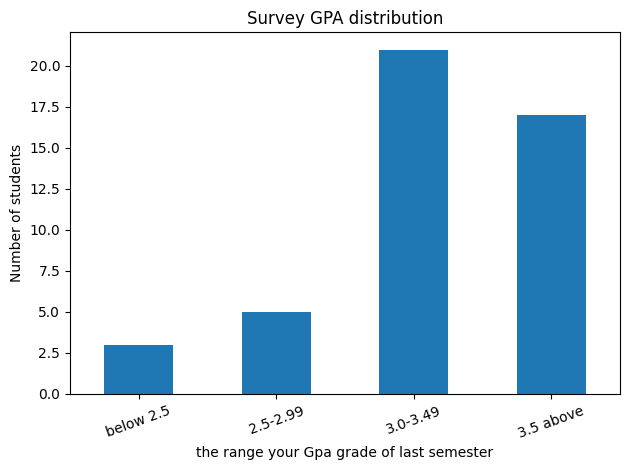

In [ ]:
survey = pd.read_excel(SURVEY_FILE, sheet_name='Cleaned Survey')
survey.columns = survey.columns.str.strip()
survey = survey.apply(lambda col: col.map(lambda v: v.strip() if isinstance(v, str) else v))
features = {
    'How much time you spent on studying per week ( outside of class time)': 'study_time',
    'How would you describe your class attendance last year': 'attendance',
    'How much time do you usually spend on revision before exams or major assessments': 'revision',
    'note_method_clean': 'notes'
}
X = survey[list(features)].rename(columns=features).replace(r'^\s*$', np.nan, regex=True)
y = survey['the range your Gpa grade of last semester']
assert y.notna().all() and set(y) == set(LABELS), '请检查 GPA 标签。'
# 相同完整答案使用同一 group 编号，不删除任何人，也不把 group 当模型输入。
answers = survey.drop(columns='Timestamp').fillna('Missing').astype(str).agg(tuple, axis=1)
groups = pd.Series(pd.factorize(answers)[0], index=survey.index)
print('问卷记录数：', len(X), '；不同完整答案数：', groups.nunique())
display(y.value_counts().reindex(LABELS).to_frame('Number of students'))
display(X.isna().sum().to_frame('Missing values'))
y.value_counts().reindex(LABELS).plot.bar(title='Survey GPA distribution', rot=20)
plt.ylabel('Number of students')
plt.tight_layout()
plt.savefig(OUT / 'survey_gpa_distribution.png', dpi=150)
plt.show()


## 3. 简单、公平的模型比较方法
**L6：训练与测试分开。** 一次固定随机划分：约 80% 训练、20% 测试，按 GPA 比例分层。问卷按完整答案组划分，所以记录数可能不刚好是 80/20。

**选模型只看训练集。** 在训练集内进行一次两折交叉验证，用平均 macro-F1 选模型，然后查看所有模型在同一测试集上的表现。此处不做嵌套/重复交叉验证，不做 GridSearch，不在看到测试分数后重新选模型或改参数。两折是因为问卷训练集最低类仅约 2 人；验证分数也很不稳定。

**固定参数，理由先写清楚：**
- Decision Tree（L4–L5）：Gini；深度 3、每叶至少 2 人，限制树的复杂度。
- KNN（L7）：k=5，使用五个相似学生投票，避免只依赖一个邻居。
- SVM（L7）：linear、C=1，使用简单的线性边界。
- Baseline：不学习习惯，总猜训练集中最多的 GPA 类。允许它被选中，避免假定复杂模型一定更好。

**为什么用 Pipeline？** 它只是把“填缺失 → one-hot → 分类器”装在一起的代码工具，不是额外算法。每个训练折单独学习编码，测试数据不参与。

**L2–L3：特征转换。** 类别变成 0/1 列（one-hot）；不把 UCI 类别编号或 GPA 区间当成真实测量值。已编码的变量都为 0/1，无需另外标准化；代价是丢失类别的等级距离。未见过的类别编码为全零，可能影响预测。

**指标（L6）：** Accuracy、Precision、Recall、F1。后三个使用 macro 平均，即四类同等权重，避免多数类掩盖小类错误；未预测某类时该类 precision/F1 按 0 处理。CV 分数用于选择，test 分数用于评价，二者不能混为一谈。


survey | train: 36 | test: 10 | selected by training CV: KNN


,CV_macro_F1,Train_accuracy,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_F1_macro
Model,,,,,,
Baseline,0.154,0.444,0.5,0.125,0.250,0.167
Decision Tree,0.290,0.667,0.5,0.250,0.450,0.321
KNN,0.313,0.611,0.6,0.500,0.533,0.432
SVM,0.249,0.722,0.6,0.389,0.333,0.304


col_0,test,train
the range your Gpa grade of last semester,,
below 2.5,1,2
2.5-2.99,1,4
3.0-3.49,5,16
3.5 above,3,14


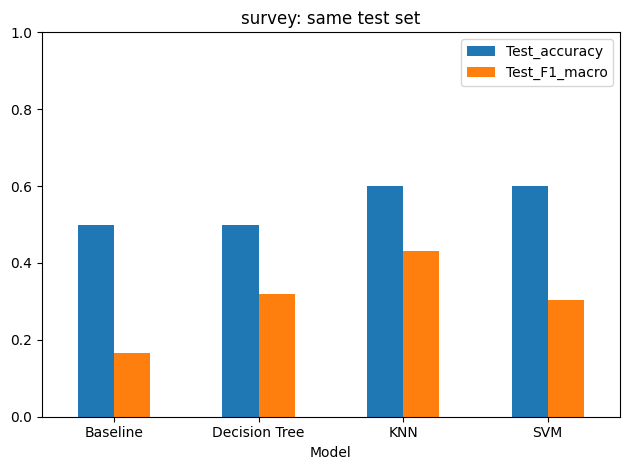

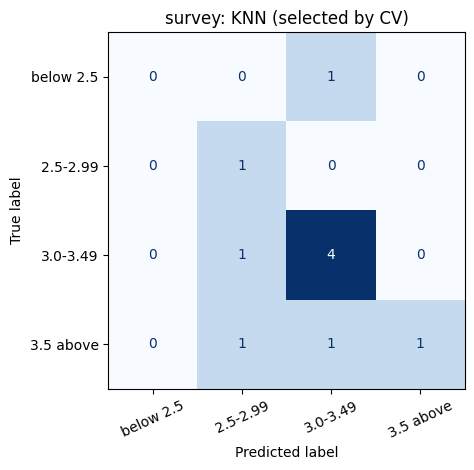

In [ ]:
def compare_models(X, y, groups, name):
    # 按完整答案组分层：相同答案不能同时进入训练和测试。
    group_table = pd.DataFrame({'group': groups, 'label': y}).drop_duplicates('group')
    assert pd.DataFrame({'g': groups, 'y': y}).groupby('g').y.nunique().max() == 1
    train_groups, test_groups = train_test_split(group_table, test_size=0.2,
                                                stratify=group_table.label, random_state=SEED)
    train_rows = groups.isin(train_groups.group)
    X_train, X_test = X[train_rows], X[~train_rows]
    y_train, y_test = y[train_rows], y[~train_rows]
    assert set(y_train) == set(y_test) == set(LABELS)
    assert set(train_groups.group).isdisjoint(test_groups.group)
    # 同样的组规则用于训练集内的两折验证；cv 中的索引相对于 X_train。
    cv = []
    splitter = StratifiedKFold(n_splits=2, shuffle=True, random_state=SEED)
    for a, b in splitter.split(train_groups, train_groups.label):
        fit = np.flatnonzero(groups[train_rows].isin(train_groups.iloc[a].group))
        val = np.flatnonzero(groups[train_rows].isin(train_groups.iloc[b].group))
        assert set(y_train.iloc[fit]) == set(y_train.iloc[val]) == set(LABELS)
        assert set(groups[train_rows].iloc[fit]).isdisjoint(groups[train_rows].iloc[val])
        cv.append((fit, val))
    classifiers = {
        'Baseline': DummyClassifier(strategy='most_frequent'),
        'Decision Tree': DecisionTreeClassifier(max_depth=3, min_samples_leaf=2, random_state=SEED),
        'KNN': KNeighborsClassifier(n_neighbors=5),
        'SVM': SVC(kernel='linear', C=1)
    }
    models, cv_scores = {}, {}
    for model_name, classifier in classifiers.items():
        model = make_pipeline(SimpleImputer(strategy='constant', fill_value='Missing', keep_empty_features=True),
                              OneHotEncoder(handle_unknown='ignore', sparse_output=False), classifier)
        cv_scores[model_name] = cross_val_score(model, X_train, y_train, cv=cv, scoring=scorer, error_score='raise')
        assert np.isfinite(cv_scores[model_name]).all()
        models[model_name] = model.fit(X_train, y_train)
    # 此行发生在任何测试预测之前。若同分，采用字典中的先后顺序。
    selected = max(cv_scores, key=lambda key: cv_scores[key].mean())
    rows, predictions = [], pd.DataFrame({'actual': y_test})
    for model_name, model in models.items():
        pred = model.predict(X_test)
        predictions[model_name] = pred
        rows.append({'Model': model_name, 'CV_macro_F1': cv_scores[model_name].mean(),
            'Train_accuracy': accuracy_score(y_train, model.predict(X_train)),
            'Test_accuracy': accuracy_score(y_test, pred),
            'Test_precision_macro': precision_score(y_test, pred, labels=LABELS, average='macro', zero_division=0),
            'Test_recall_macro': recall_score(y_test, pred, labels=LABELS, average='macro', zero_division=0),
            'Test_F1_macro': f1_score(y_test, pred, labels=LABELS, average='macro', zero_division=0)})
    table = pd.DataFrame(rows).set_index('Model')
    folder = OUT / name
    folder.mkdir(exist_ok=True)
    table.to_csv(folder / 'comparison.csv')
    pd.DataFrame(cv_scores, index=['fold1', 'fold2']).to_csv(folder / 'cv_scores.csv')
    predictions.to_csv(folder / 'test_predictions.csv', index_label='source_row_zero_based')
    pd.DataFrame({'group': groups, 'set': np.where(train_rows, 'train', 'test')}).to_csv(folder / 'split.csv')
    report = classification_report(y_test, predictions[selected], labels=LABELS, output_dict=True, zero_division=0)
    pd.DataFrame({k: v for k, v in report.items() if isinstance(v, dict)}).T.to_csv(folder / 'selected_classification_report.csv')
    joblib.dump(models[selected], folder / 'selected_model.joblib')
    (folder / 'selected_model.txt').write_text(selected, encoding='utf-8')
    print(name, '| train:', len(X_train), '| test:', len(X_test), '| selected by training CV:', selected)
    display(table.round(3))
    display(pd.crosstab(y, np.where(train_rows, 'train', 'test')).reindex(LABELS))
    table[['Test_accuracy', 'Test_F1_macro']].plot.bar(ylim=(0, 1), rot=0, title=name + ': same test set')
    plt.tight_layout()
    plt.savefig(folder / 'comparison.png', dpi=150)
    plt.show()
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[selected], labels=LABELS,
        display_labels=LABELS, cmap='Blues', colorbar=False, xticks_rotation=25)
    plt.title(name + ': ' + selected + ' (selected by CV)')
    plt.tight_layout()
    plt.savefig(folder / 'confusion_matrix.png', dpi=150)
    plt.show()
    return models[selected], models['Decision Tree'], table

survey_model, survey_tree, survey_table = compare_models(X, y, groups, 'survey')


## 4. UCI：用相同代码单独比较
根据组员提供的字典，Last_Semester_GPA 的 1/2 分别为 <2.00、2.00–2.49，合并为 below 2.5；3/4/5 分别对应其余三类。**Grade 是课程成绩，不是本项目的 GPA 目标；Expected_GPA 也不能作为输入。**

只使用四种习惯。UCI 的笔记频率和问卷的笔记方式并不相同，其他选项也不同，所以分别训练，不拼成 191 行，不声称这是对问卷模型的外部验证。比较的是各数据集内部的算法表现。


uci | train: 116 | test: 29 | selected by training CV: KNN


,CV_macro_F1,Train_accuracy,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_F1_macro
Model,,,,,,
Baseline,0.138,0.379,0.379,0.095,0.250,0.138
Decision Tree,0.190,0.483,0.414,0.252,0.298,0.252
KNN,0.267,0.440,0.448,0.244,0.338,0.280
SVM,0.209,0.448,0.345,0.187,0.244,0.195


col_0,test,train
Last_Semester_GPA,,
below 2.5,11,44
2.5-2.99,5,20
3.0-3.49,8,32
3.5 above,5,20


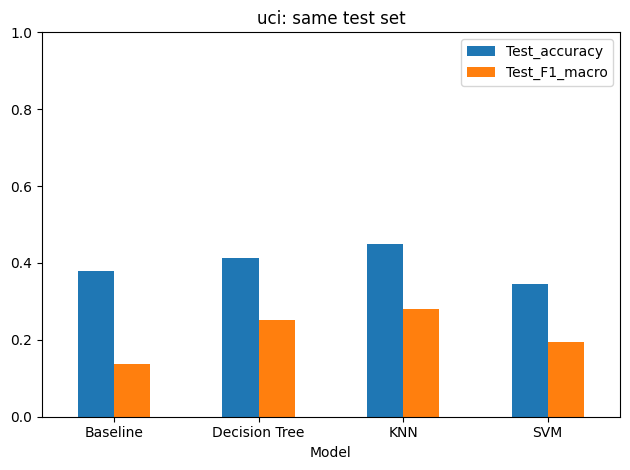

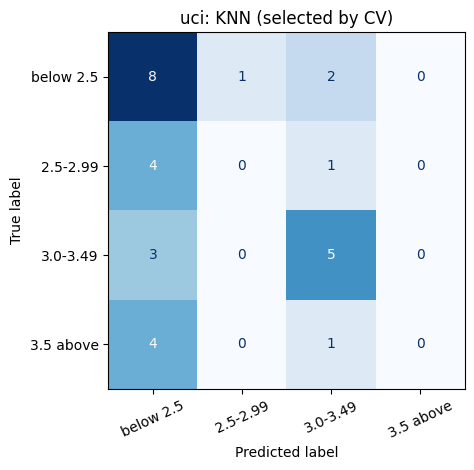

In [ ]:
if RUN_UCI:
    uci = pd.read_excel(UCI_FILE, sheet_name='UCI_Cleaned')
    uci_features = ['Weekly_Study_Hours', 'Class_Attendance', 'Exam_Prep_Timing', 'Note_Taking']
    allowed = {'Weekly_Study_Hours': [1,2,3,4,5], 'Class_Attendance': [1,2,3],
               'Exam_Prep_Timing': [1,2,3], 'Note_Taking': [1,2,3], 'Last_Semester_GPA': [1,2,3,4,5]}
    for col, codes in allowed.items():
        assert uci[col].notna().all() and uci[col].isin(codes).all(), '请核对 UCI 数据字典。'
    assert uci.Student_ID.notna().all() and uci.Student_ID.is_unique
    X_uci = uci[uci_features].astype(int).astype(str)  # 编号作为类别，而非真实时长
    y_uci = uci.Last_Semester_GPA.map({1: LABELS[0], 2: LABELS[0], 3: LABELS[1], 4: LABELS[2], 5: LABELS[3]})
    uci_groups = pd.Series(np.arange(len(uci)), index=uci.index)
    uci_model, uci_tree, uci_table = compare_models(X_uci, y_uci, uci_groups, 'uci')


## 5. 看懂决策树（L4–L5）
方框中的条件是 one-hot 特征是否为 1。例如某一学习时间类别 `<=0.5` 表示“不属于该类别”。Gini 越低，节点中的 GPA 类别越一致。

这棵树只在训练集上学习。它可以帮助说明分类过程，但树的分支不是因果证据；即使最终选择了其他模型，也可以把树作为可解释的比较模型。


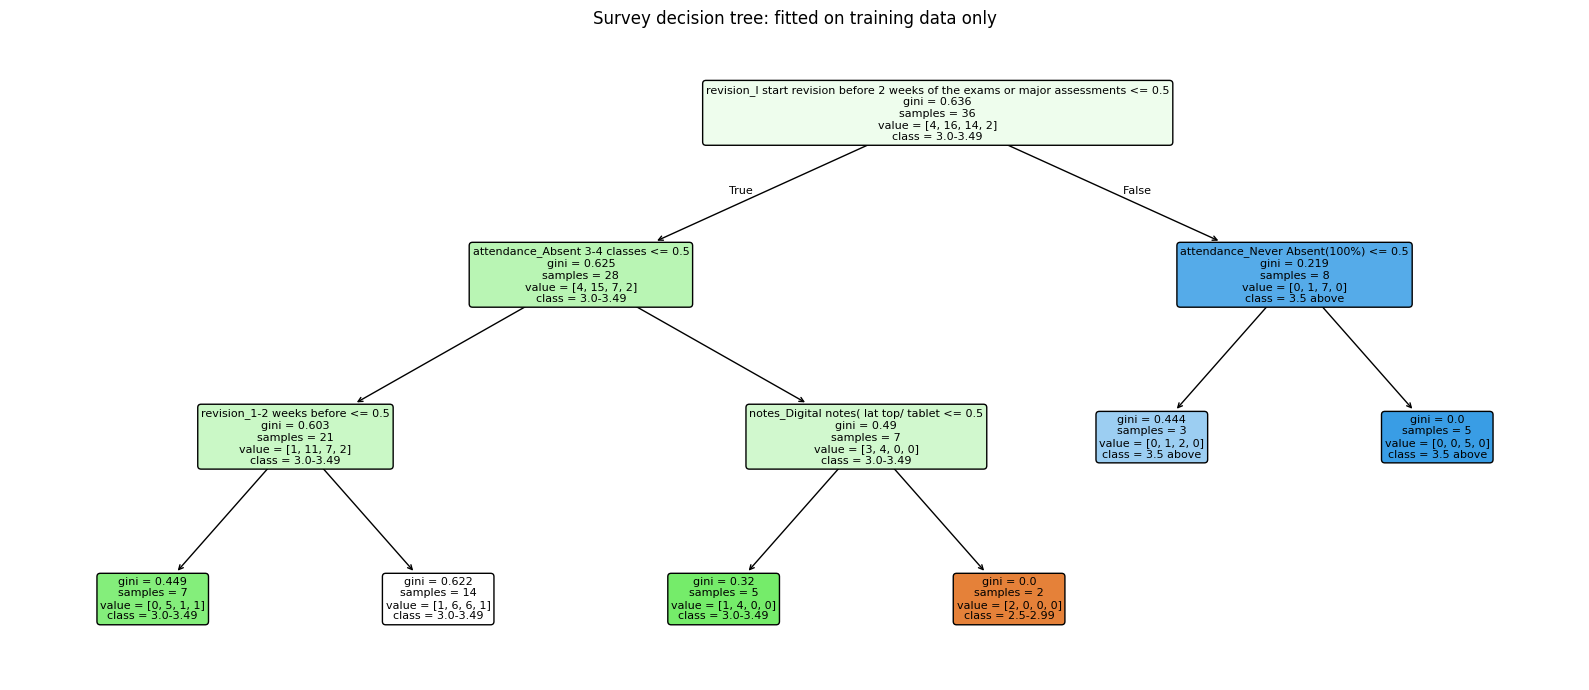

In [ ]:
tree = survey_tree.steps[-1][1]
feature_names = survey_tree.steps[1][1].get_feature_names_out(X.columns)
plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=feature_names, class_names=list(tree.classes_),
          filled=True, rounded=True, fontsize=8)
plt.title('Survey decision tree: fitted on training data only')
plt.tight_layout()
plt.savefig(OUT / 'survey' / 'decision_tree.png', dpi=150)
plt.show()


## 6. 对新样本分类：满足“应用模型”部分
下面是**人为编写的演示学生**，没有真实 GPA 标签，不属于测试样本。可修改四项信息后重新预测。分类器给的是区间，不是准确 GPA，也不是学习建议。若训练 CV 选了 Baseline，输出将与习惯无关，应如实说明。

预测新样本使用此前选好的、只在训练集上拟合的模型。没有在测试后重新选模型或用全部数据重新训练。


In [ ]:
new_student = pd.DataFrame([{
    'study_time': '6-10 hours',
    'attendance': 'Never Absent(100%)',
    'revision': '1-2 weeks before',
    'notes': 'Both Handwritten and Digital'
}])
new_student['predicted_GPA_range'] = survey_model.predict(new_student)
display(new_student)
new_student.to_csv(OUT / 'survey' / 'new_student_example.csv', index=False)

if RUN_UCI:
    # 字典：2=每周<5小时，1=总出勤，2=规律准备，3=总记笔记。
    new_uci_student = pd.DataFrame([{'Weekly_Study_Hours': '2', 'Class_Attendance': '1',
                                   'Exam_Prep_Timing': '2', 'Note_Taking': '3'}])
    new_uci_student['predicted_GPA_range'] = uci_model.predict(new_uci_student)
    display(new_uci_student)
    new_uci_student.to_csv(OUT / 'uci' / 'new_student_example.csv', index=False)


,study_time,attendance,revision,notes,predicted_GPA_range
0,6-10 hours,Never Absent(100%),1-2 weeks before,Both Handwritten and Digital,3.0-3.49


,Weekly_Study_Hours,Class_Attendance,Exam_Prep_Timing,Note_Taking,predicted_GPA_range
0,2,1,2,3,2.5-2.99


## 7. 检查 AI 代码是否有效，以及如何解读
代码中的 assert 已检查合法标签、各类覆盖、相同答案的隔离；下面再手工验证 Accuracy。不是只说“AI 已检查”。

**读结果的顺序：**
1. 看训练 CV 选中了哪个模型，不把测试最高分者重新指定成最终模型。
2. 对照 Baseline。Accuracy 高可能只是多数类猜对；macro-F1 反映是否照顾到四类。
3. 看 confusion matrix：行是真实 GPA，列是预测 GPA；对角线是正确分类。
4. 比较训练/测试 accuracy：训练明显高于测试可能提示过拟合，但小测试集也会带来波动。
5. 单次划分不能证明哪个算法显著更好，也不能证明习惯引起 GPA 改变。

**简化的代价：** 问卷测试集中最低类仅约 1 人。分数对个别预测和划分十分敏感，不提供显著性检验或可靠个体建议。且这是对上一学期自报 GPA 的分类，未验证未来 GPA 预测；样本量、抽样、自报误差和未控制的学科/能力等都会影响结果。数据量不足的限制不能靠复杂算法消除。


In [ ]:
datasets = ['survey', 'uci'] if RUN_UCI else ['survey']
for name in datasets:
    saved = pd.read_csv(OUT / name / 'test_predictions.csv')
    table = pd.read_csv(OUT / name / 'comparison.csv', index_col='Model')
    for model_name in table.index:
        manual_accuracy = (saved.actual == saved[model_name]).mean()
        assert np.isclose(manual_accuracy, table.loc[model_name, 'Test_accuracy'])
    print(name, ': PASS — 手工计算的正确数/测试人数与所有模型的 accuracy 一致。')
print('完成。比较表、图、新样本结果和模型已导出至', OUT.resolve())


survey : PASS — 手工计算的正确数/测试人数与所有模型的 accuracy 一致。
uci : PASS — 手工计算的正确数/测试人数与所有模型的 accuracy 一致。
完成。比较表、图、新样本结果和模型已导出至 /content/simple_results


## 本次运行的具体结论（固定输入和 seed=42）

| 数据 | 训练/测试 | 训练 CV 选中的模型 | 测试正确数 | 测试 macro-F1 |
|---|---|---|---|---|
| 问卷 | 36 / 10 | KNN | 6 / 10 | 0.432 |
| UCI | 116 / 29 | KNN | 13 / 29 | 0.280 |

问卷 Baseline 为 5/10，macro-F1=0.167；KNN 仅多分对 1 人，不能据此说它稳定优于基准。KNN 未识别出测试集中唯一一位 below 2.5 的学生；3.5 above 类只分对 1/3，因此不能只报告 60%。

UCI Baseline 为 11/29，KNN 为 13/29；KNN 在 2.5–2.99 和 3.5 above 两类的 recall 都是 0，说明类别识别仍不均衡。

问卷新样本演示输出 3.0–3.49；UCI 新样本演示输出 2.5–2.99。它们无已知真值，不能计入准确率。更换数据或设置后，应根据新输出更新本段和报告，不复用旧结论。
